# Spectral Clustering
### TMA4205 Numerical Linear Algebra

In [3]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.linalg as la
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import KMeans

In [2]:
# Hand-out code
point_size = 10
plt.ion()

def make_data(n=100, sigma = 0.5, pl=False):
    '''
    Make four clusters: noisy data points around 4 centres.
    
    Parameters:
    n: number of points in each cluster (default 100)
    sigma: Level of noise (default 0.5)
    pl: Make a plot or not  (default False)

    Return:
    X: the data points, np.array of shape (4*n,2)
    '''
    centers = np.array([[0, 0],[1, 5],[4, 0],[5, 5]])
    X = np.vstack([center + sigma * np.random.randn(n, 2) for center in centers])
    if pl:
        plt.clf()
        plt.scatter(X[:, 0], X[:, 1], s=point_size)
        plt.axis('equal')
    return X


def make_moons(n = 150, sigma = 0.12, pl = False):
    '''
    Make four interleaving half circles.

    Parameters:
    n: Number of data points in each half circle (default 150)
    sigma : Noise level, or the spread of data (default 0.12)
    pl:  Make a plot or not  (default False)

    Return:
    X: The data points, np.array of shape (4*n,2)
    '''
    X = []
    labels = []
    # Four moons, separated spatially
    centers = [(0, 0), (1, 0), (-2.5, -2), (-1, -2)]
    for j, (cx, cy) in enumerate(centers):
        t = np.linspace(0, np.pi, n)
        x = 1.5 * np.cos(t)
        y = 1.5 * np.sin(t)
        # Put the four moons in different orientations
        if j == 1:
            y = -y
        elif j == 2:
            x = -x
        elif j == 3:
            x = -x
            y = -y
        x += cx + 0.12*np.random.randn(n)
        y += cy + 0.12*np.random.randn(n)
        X.append(np.column_stack((x, y)))
        labels.extend([j]*n)
    X = np.vstack(X)
    labels = np.array(labels)

    if pl:
        plt.clf()
        plt.scatter(X[:,0], X[:,1], c=labels, s=point_size)
        plt.axis("equal")
        plt.show()
    return X

### Part 1: Understanding spectral clustering

In this task we construct a symmetric $k$-nearest-neighbour graph and assign weights to its edges using the Gaussian similarity function
$$
s(x_i, x_j) = exp \left( \frac{- ||x_i - x_j||_2^2}{2 \sigma^2} \right)
$$
where $\sigma$ controls the width of the neighbourhood.

The unnormalized graph Laplacian matrix is defined as 
$$ L = D - W$$
**Proposition 1 (Properties of $L$).** *The matrix $L$ satisfies the following properties:*

1. *For every vector $f \in \mathbb{R}^n$ we have*
$$
f' L f = \frac{1}{2} \sum_{i,j=1}^{n} w_{ij} (f_i - f_j)^2.
$$
2. *$L$ is symmetric and positive semi-definite.*
3. *The smallest eigenvalue of $L$ is $0$, the corresponding eigenvector is the constant one vector $\mathbb{1}$.*
4. *$L$ has $n$ non-negative, real-valued eigenvalues $0 = \lambda_1 \leq \lambda_2 \leq \dots \leq \lambda_n$.*

In [14]:
def make_laplacian(X, k = 10, sigma = None):
    '''
    Make the unnormalized graph Laplacian L = D - W of a symmetric
    k-nearest-neighbour graph with Gaussian edge weights.

    Parameters:
    X: The data points, np.array of shape (n,d)
    k: Number of nearest neighbours (default 10)
    sigma: Width of the Gaussian similarity function. If None, the mean
           distance from a point to its k-th nearest neighbour is used (default None)

    Return:
    W: Weighted adjacency matrix, scipy sparse matrix of shape (n,n)
    L: Graph Laplacian, scipy sparse matrix of shape (n,n)
    sigma: The value of sigma that was used
    '''
    # Directed kNN graph, entries are the distances ||x_i - x_j||
    A = kneighbors_graph(X, n_neighbors=k, mode="distance", include_self=False)

    if sigma is None:
        sigma = np.asarray(A.max(axis=1).todense()).mean()

    # Make symmetric: edge if i is among the kNN of j OR j among the kNN of i
    A = A.maximum(A.T).tocsr()

    # Gaussian weights on the existing edges only (keeps W sparse)
    W = A.copy()
    W.data = np.exp(-W.data**2 / (2 * sigma**2))

    d = np.asarray(W.sum(axis=1)).ravel()
    L = (sp.diags(d) - W).tocsr()
    return W, L, sigma

In [21]:
def spectral_clustering(X, K, k = 10, sigma = None):
    '''
    Unnormalized spectral clustering (von Luxburg, Sec. 4).

    Parameters:
    X: The data points, np.array of shape (n,d)
    K: Number of clusters
    k: Number of nearest neighbours in the graph (default 10)
    sigma: Width of the Gaussian similarity function (default None, see make_laplacian)
    pl: Make a plot or not (default False)

    Return:
    labels: Cluster label of each data point, np.array of shape (n,)
    eigenvals: Eigenvalues of L in ascending order, np.array of shape (n,)
    U: The first K eigenvectors of L as columns, np.array of shape (n,K)
    '''
    W, L, sigma = make_laplacian(X, k, sigma)

    # Standard dense solver, returns eigenvalues in ascending order
    eigenvals, V = la.eigh(L.toarray())
    U = V[:, :K]

    labels = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(U)

    return labels, eigenvals, U

In [53]:
def plot_result(X, labels, lam, K, m = 15, title = None, fname = None):
    '''
    Make two separate figures: the clustering, and the smallest eigenvalues of L.
    All plot styling is contained in this function.

    Parameters:
    X: The data points, np.array of shape (n,2)
    labels: Cluster label of each point, np.array of shape (n,)
    lam: Eigenvalues of L in ascending order, np.array of shape (n,)
    K: Number of clusters
    m: Number of eigenvalues to plot (default 15)
    title: Title prefix for both figures (default None)
    fname: File name prefix, e.g. "moons" gives moons_clusters.pdf and
           moons_eigenvalues.pdf (default None, nothing is saved)
    '''
    
    colors = ["#E85D9E", "#FF8C42", "#4DA3E0", "#F7B731","#F26B6B",
              "#9B6BD6", "#3FC38B", "#1B5E3F",]
    style = {
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
        "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.alpha": 0.25,
        "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    }
    prefix = f"{title} " if title else ""

    with plt.rc_context(style):
        # Figure 1: clusters
        fig1, ax1 = plt.subplots(figsize=(8, 6))
        for c in np.unique(labels):
            mask = labels == c
            ax1.scatter(X[mask, 0], X[mask, 1], s=14, color=colors[c % len(colors)],
                        edgecolor="white", linewidth=0.3, label=f"Cluster {c+1}")
        ax1.set_aspect("equal", adjustable="datalim")
        ax1.set_title(prefix, fontsize=14)
        ax1.grid(False)
        if fname:
            fig1.savefig(f"{fname}_clusters.pdf")
        plt.show()

        # Figure 2: eigenvalues
        fig2, ax2 = plt.subplots(figsize=(8, 4))
        idx = np.arange(1, m + 1)
        ax2.plot(idx, lam[:m], "-", color="0.6", linewidth=1, zorder=1)
        ax2.scatter(idx[:K], lam[:K], color=colors[0], s=35, zorder=2,
                    label=f"First $K={K}$")
        ax2.scatter(idx[K:], lam[K:m], color="0.5", s=35, zorder=2)
        ax2.axvline(K + 0.5, color="0.4", linestyle="--", linewidth=1)
        ax2.set_xlabel("Index $i$")
        ax2.set_ylabel(r"$\lambda_i$")
        ax2.set_xticks(idx[::2])
        ax2.set_title(r"Eigenvalues of $L$", fontsize=14)
        ax2.legend(frameon=False)
        if fname:
            fig2.savefig(f"{fname}_eigenvalues.pdf")
        plt.show()

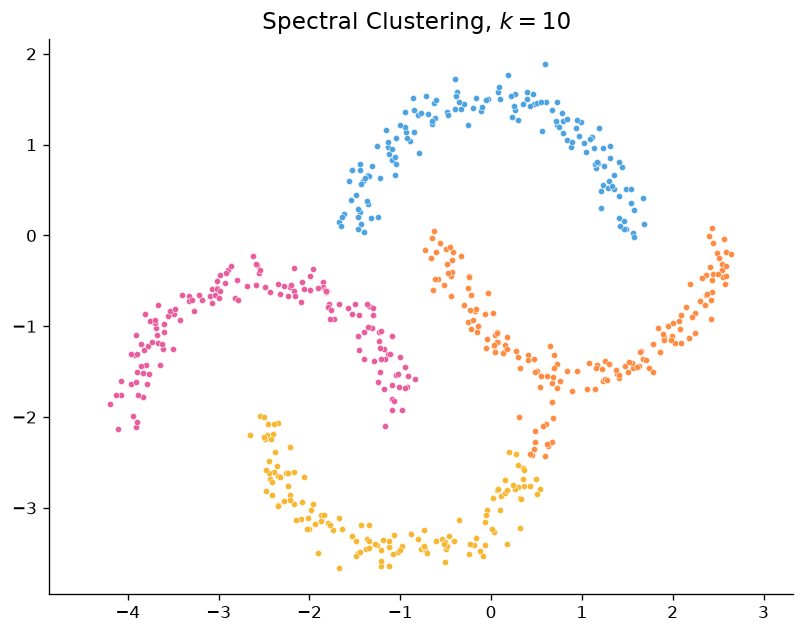

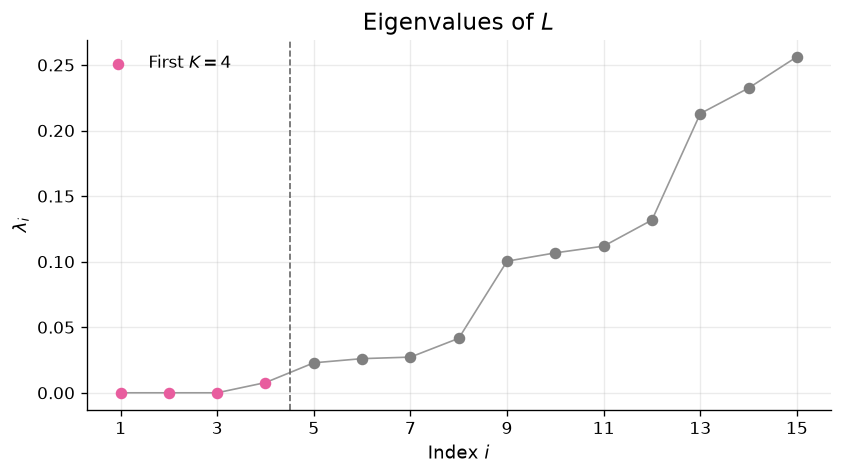

In [54]:
np.random.seed(42)
X = make_moons()
labels, lam, U = spectral_clustering(X, K=4, k=10)
plot_result(X, labels, lam, K=4, title="Spectral Clustering, $k=10$", fname="moons.pdf")